In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
path = r"C:\Users\Newtouch\Desktop\funnel-drop-analysis-main (0)\funnel-drop-analysis-main\funnel-drop-data.csv.csv"


In [3]:

import pandas as pd
path = r"C:\Users\Newtouch\Desktop\funnel-drop-analysis-main (0)\funnel-drop-analysis-main\funnel-drop-data.csv.csv"
df = pd.read_csv(path)
print("Data loaded successfully!")
print(df.shape)
print(df.columns.tolist())


Data loaded successfully!
(12719, 10)
['SessionID', 'UserID', 'Timestamp', 'PageType', 'DeviceType', 'Country', 'ReferralSource', 'TimeOnPage_seconds', 'ItemsInCart', 'Purchased']


In [4]:
# Missing values and data types
import pandas as pd
print("\nNull values per column:\n", df.isnull().sum())


Null values per column:
 SessionID             0
UserID                0
Timestamp             0
PageType              0
DeviceType            0
Country               0
ReferralSource        0
TimeOnPage_seconds    0
ItemsInCart           0
Purchased             0
dtype: int64


<a id="data-cleaning"></a>
## Checking for Missing Values  

Before doing any kind of analysis, we must make sure our data is **complete**  meaning there are no empty or missing cells. Missing values can cause wrong results when we make graphs or build models, so this step is very important.

---

In [5]:
# Data types summary
print("\nData types:\n", df.dtypes)


Data types:
 SessionID               str
UserID                  str
Timestamp               str
PageType                str
DeviceType              str
Country                 str
ReferralSource          str
TimeOnPage_seconds    int64
ItemsInCart           int64
Purchased             int64
dtype: object


In [6]:
# Basic numeric summary
df.describe()

,TimeOnPage_seconds,ItemsInCart,Purchased
count,12719.000000,12719.000000,12719.000000
mean,97.427707,1.138533,0.397044
std,48.120729,1.689954,0.489304
min,15.000000,0.000000,0.000000
25%,56.000000,0.000000,0.000000
50%,98.000000,0.000000,0.000000
75%,139.000000,2.000000,1.000000
max,180.000000,5.000000,1.000000


In [7]:
# Exploring from Timestamp ---

print("Original Timestamp dtype:", df['Timestamp'].dtype)

# Convert Timestamp column to datetime objects
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# Extract new time-based features
df['HourOfDay'] = df['Timestamp'].dt.hour
df['DayOfWeek'] = df['Timestamp'].dt.day_name()
df['Date'] = df['Timestamp'].dt.date
df['Month'] = df['Timestamp'].dt.month
df['Month_Name'] = df['Timestamp'].dt.month_name() 

print("New time-based features created.")
df[['Timestamp', 'HourOfDay', 'DayOfWeek', 'Date', 'Month_Name']].head()

Original Timestamp dtype: str
New time-based features created.


,Timestamp,HourOfDay,DayOfWeek,Date,Month_Name
0,2025-01-20 22:53:34,22,Monday,2025-01-20,January
1,2025-02-26 12:57:10,12,Wednesday,2025-02-26,February
2,2025-02-26 12:59:11,12,Wednesday,2025-02-26,February
3,2025-06-24 15:40:46,15,Tuesday,2025-06-24,June
4,2025-06-11 07:21:02,7,Wednesday,2025-06-11,June


In [8]:
# Checking the date range
print(f"Number of unique dates: {df['Date'].nunique()}")
print(f"Data starts on: {df['Date'].min()}")
print(f"Data ends on: {df['Date'].max()}")

Number of unique dates: 243
Data starts on: 2025-01-01
Data ends on: 2025-08-31


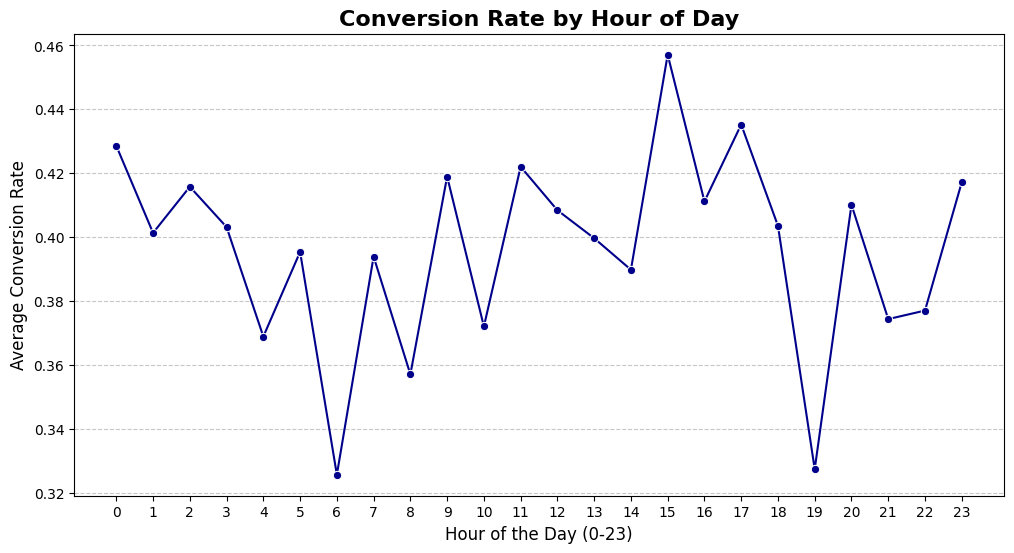

In [9]:
# Conversion Rate by Hour of Day
import matplotlib.pyplot as plt
import seaborn as sns
hourly_conv = df.groupby('HourOfDay')['Purchased'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=hourly_conv, x='HourOfDay', y='Purchased', marker='o', color='darkblue')
plt.title('Conversion Rate by Hour of Day', fontsize=16, weight='bold')
plt.xlabel('Hour of the Day (0-23)', fontsize=12)
plt.ylabel('Average Conversion Rate', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

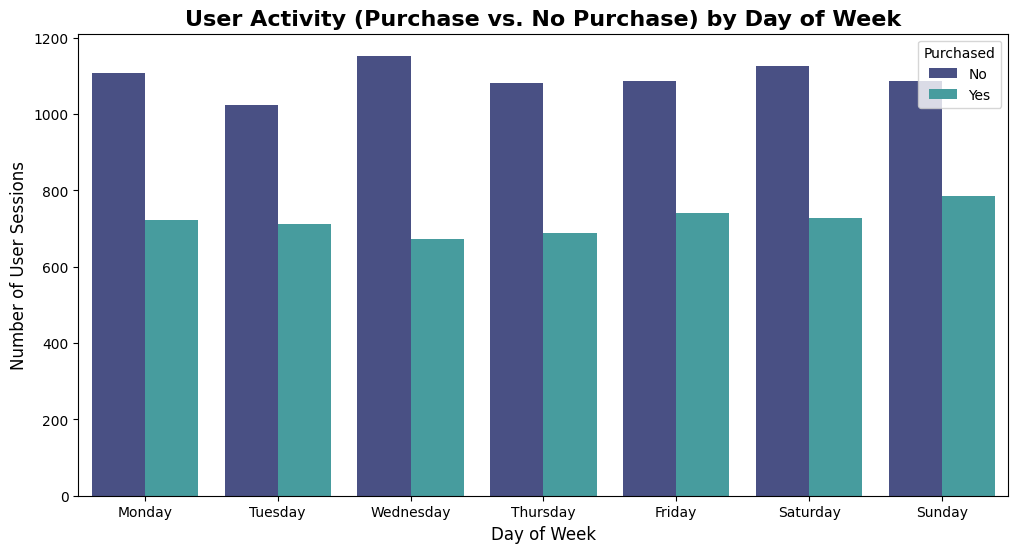

In [10]:
# # --- Analysis: Purchases vs. Day of Week ---
plt.figure(figsize=(12, 6))
# We specify the order to ensure it's not alphabetical
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

sns.countplot(data=df, x='DayOfWeek', hue='Purchased', order=day_order, palette='mako')
plt.title('User Activity (Purchase vs. No Purchase) by Day of Week', fontsize=16, weight='bold')
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('Number of User Sessions', fontsize=12)
plt.legend(title='Purchased', labels=['No', 'Yes'])
plt.show()

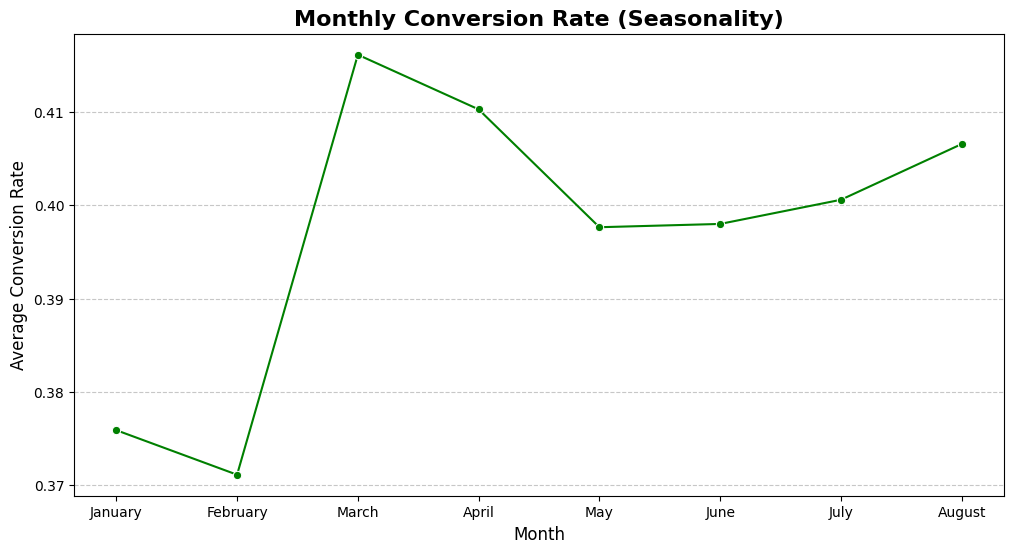

In [11]:
# Conversion Rate by Month ---
monthly_conv = df.groupby('Month_Name')['Purchased'].mean().reset_index()

# Sort by month number to ensure correct order
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']
monthly_conv['Month_Name'] = pd.Categorical(monthly_conv['Month_Name'], categories=month_order, ordered=True)
monthly_conv = monthly_conv.sort_values('Month_Name')

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_conv, x='Month_Name', y='Purchased', marker='o', color='green')
plt.title('Monthly Conversion Rate (Seasonality)', fontsize=16, weight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average Conversion Rate', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [12]:
# Funnel Drop-Off Analysis ---

# Define the logical order of the funnel steps
funnel_steps = ['home', 'product_page', 'cart', 'checkout', 'confirmation']

# Get unique user/session counts for each page type Using SessionID assuming one session represents one user's funnel attempt
page_counts = df.groupby('PageType')['SessionID'].nunique().reindex(funnel_steps).reset_index()
page_counts.columns = ['PageType', 'UserCount']

# Calculate step-to-step conversion percentage
page_counts['To_Next_Step_Conversion_%'] = 100 * (page_counts['UserCount'].shift(-1) / page_counts['UserCount'])

# Calculate overall conversion percentage from the 'Home' step
page_counts['Overall_Conversion_%'] = 100 * (page_counts['UserCount'] / page_counts['UserCount'].iloc[0])

page_counts['To_Next_Step_Conversion_%'].fillna(0, inplace=True)
print("\nFunnel Step-by-Step Conversion:")

# Display the table
display(page_counts.style.format({'To_Next_Step_Conversion_%': '{:.2f}%', 'Overall_Conversion_%': '{:.2f}%'}))

C:\Users\Newtouch\AppData\Local\Temp\ipykernel_3016\3188323405.py:16: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  page_counts['To_Next_Step_Conversion_%'].fillna(0, inplace=True)



Funnel Step-by-Step Conversion:


,PageType,UserCount,To_Next_Step_Conversion_%,Overall_Conversion_%
0,home,5000,79.74%,100.00%
1,product_page,3987,40.11%,79.74%
2,cart,1599,70.23%,31.98%
3,checkout,1123,89.94%,22.46%
4,confirmation,1010,nan%,20.20%


In [13]:
# Time Spent in Funnel (Time to Conversion) ---

# Calculate time difference within each session from first event to last event
df['SessionDuration_seconds'] = df.groupby('SessionID')['Timestamp'].transform(lambda x: (x.max() - x.min()).total_seconds())

# Filter for completed sessions (those reaching confirmation)
completed_sessions = df[df['PageType'] == 'confirmation']['SessionID'].unique()
df_completed = df[df['SessionID'].isin(completed_sessions)]

# Calculate average time to conversion for completed sessions
avg_time_to_conv = df_completed.groupby('SessionID')['SessionDuration_seconds'].first().mean()

print(f"Average Time from First Page to Confirmation (for converters): {avg_time_to_conv:.2f} seconds")

# Optional: Compare average session duration for buyers vs non-buyers overall
avg_duration_comparison = df.groupby('Purchased')['SessionDuration_seconds'].mean().reset_index()
print("\nAverage Session Duration Comparison:")
display(avg_duration_comparison)

Average Time from First Page to Confirmation (for converters): 388.24 seconds

Average Session Duration Comparison:


,Purchased,SessionDuration_seconds
0,0,114.004433
1,1,388.237624


Conversion Rate by Country (Top 10):


,Country,Purchased
2,France,42.93%
6,USA,40.65%
4,India,40.41%
5,UK,39.08%
1,Canada,38.36%
0,Australia,38.10%
3,Germany,37.97%


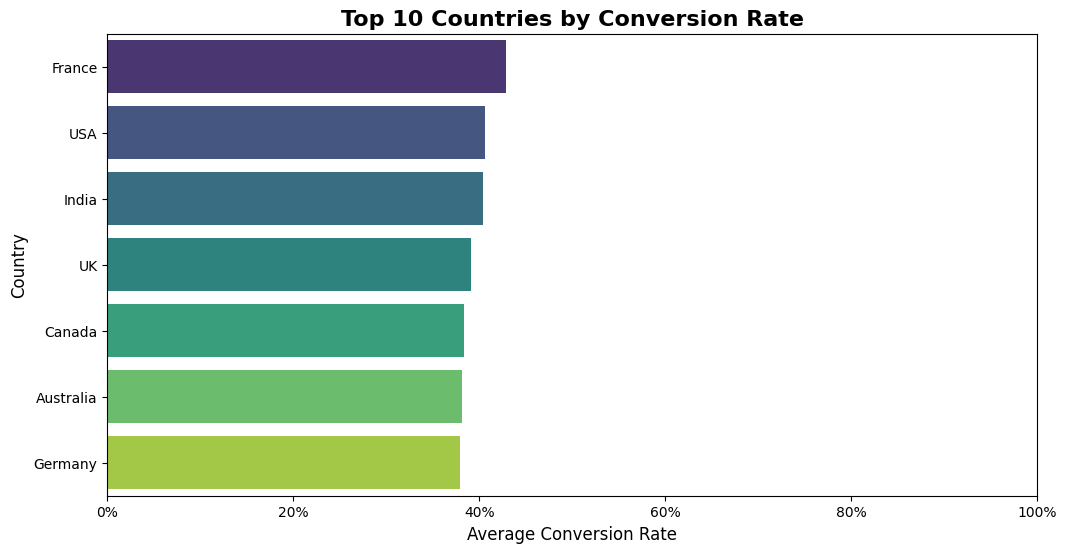

In [14]:
# Conversion Rate by Country ---

country_conv = df.groupby('Country')['Purchased'].mean().reset_index().sort_values('Purchased', ascending=False)

print("Conversion Rate by Country (Top 10):")
display(country_conv.head(10).style.format({'Purchased': '{:.2%}'})) # Show as percentage

# Plotting the top 10 countries
plt.figure(figsize=(12, 6))
sns.barplot(data=country_conv.head(10), x='Purchased', y='Country', palette='viridis', hue='Country')
plt.title('Top 10 Countries by Conversion Rate', fontsize=16, weight='bold')
plt.xlabel('Average Conversion Rate', fontsize=12)
plt.ylabel('Country', fontsize=12)
plt.xlim(0, 1) # Set x-axis limit from 0 to 1 (or 100%)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter('{:.0%}'.format)) # Format x-axis as percentage
plt.show()

Conversion Rate by Items in Cart (at Cart/Checkout/Confirm stages):


,ItemsInCart,Purchased
0,0,92.13%
1,1,78.12%
2,2,72.88%
3,3,78.78%
4,4,74.95%
5,5,72.22%


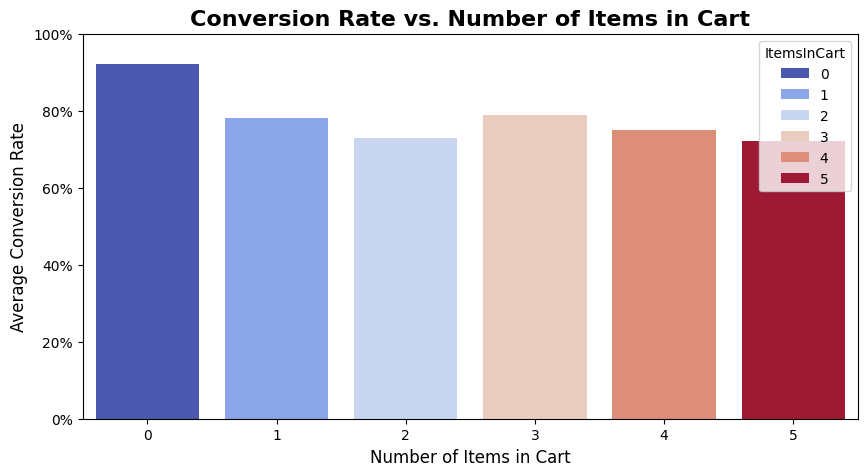

In [15]:
# Conversion Rate by Number of Items in Cart ---

# Consider only stages where items *could* be in cart (Cart, Checkout, Confirmation)
cart_stages_df = df[df['PageType'].isin(['cart', 'checkout', 'confirmation'])]

# Group by items in cart (at these stages) and calculate conversion rate
items_conv = cart_stages_df.groupby('ItemsInCart')['Purchased'].mean().reset_index()

print("Conversion Rate by Items in Cart (at Cart/Checkout/Confirm stages):")
display(items_conv.style.format({'Purchased': '{:.2%}'}))

# Plot the conversion rate
plt.figure(figsize=(10, 5))
sns.barplot(data=items_conv, x='ItemsInCart', y='Purchased', palette='coolwarm', hue='ItemsInCart')
plt.title('Conversion Rate vs. Number of Items in Cart', fontsize=16, weight='bold')
plt.xlabel('Number of Items in Cart', fontsize=12)
plt.ylabel('Average Conversion Rate', fontsize=12)
plt.ylim(0, 1)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter('{:.0%}'.format)) # Format y-axis as percentage
plt.show()

In [16]:
# Check if conversion flag exists
if 'Purchased' in df.columns:
    conv_rate = df['Purchased'].mean()
    print(f"Overall Conversion Rate: {conv_rate:.2%}")
else:
    print("No 'Purchased' column found.")

Overall Conversion Rate: 39.70%


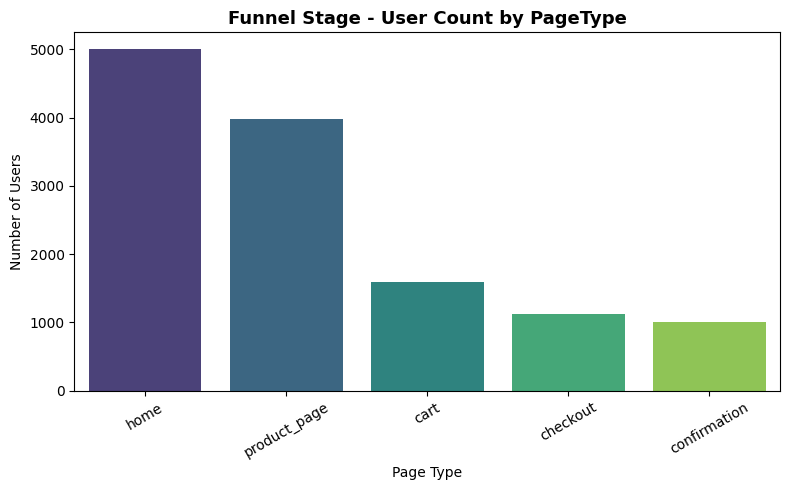

In [17]:
# Count of users per PageType
stage_counts = df['PageType'].value_counts().reset_index()
stage_counts.columns = ['PageType', 'UserCount']

plt.figure(figsize=(8,5))
sns.barplot(data=stage_counts, x='PageType', y='UserCount', hue='PageType', palette='viridis')
plt.title('Funnel Stage - User Count by PageType', fontsize=13, weight='bold')
plt.xlabel('Page Type')
plt.ylabel('Number of Users')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

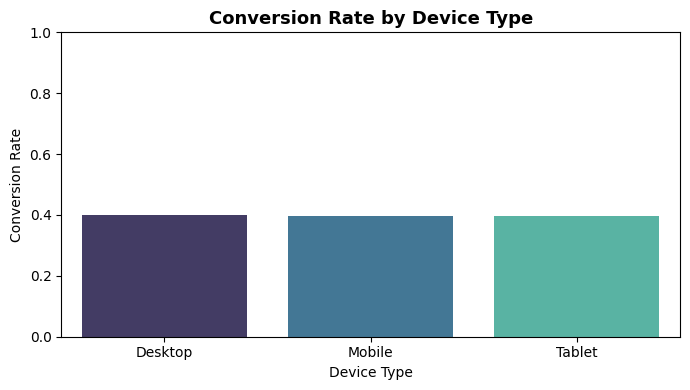

In [18]:
# Conversion rate by device
device_conv = df.groupby('DeviceType')['Purchased'].mean().reset_index()

plt.figure(figsize=(7,4))
sns.barplot(data=device_conv, x='DeviceType', y='Purchased', hue='DeviceType', palette='mako')
plt.title('Conversion Rate by Device Type', fontsize=13, weight='bold')
plt.ylabel('Conversion Rate')
plt.xlabel('Device Type')
plt.ylim(0,1)
plt.tight_layout()
plt.show()


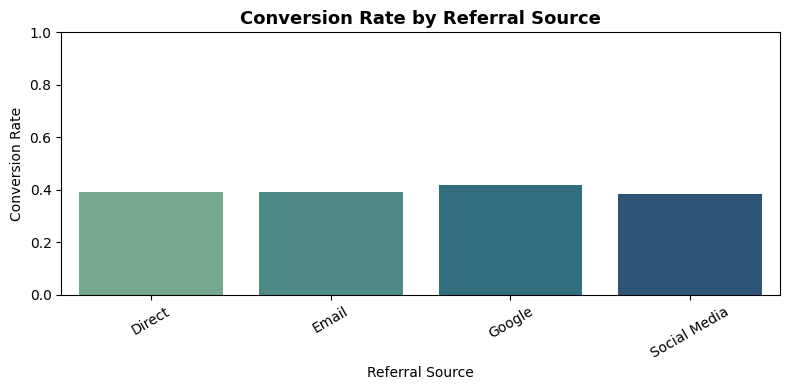

,ReferralSource,Purchased
0,Direct,0.393459
1,Email,0.390722
2,Google,0.419189
3,Social Media,0.383628


In [19]:
ref_conv = df.groupby('ReferralSource')['Purchased'].mean().reset_index()

plt.figure(figsize=(8,4))
sns.barplot(data=ref_conv, x='ReferralSource', y='Purchased', hue='ReferralSource', palette='crest')
plt.title('Conversion Rate by Referral Source', fontsize=13, weight='bold')
plt.ylabel('Conversion Rate')
plt.xlabel('Referral Source')
plt.ylim(0,1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

ref_conv

In [20]:
# Step-to-Step Conversion by Referral Source ---

# Group by ReferralSource and PageType, count unique sessions
ref_segmented_counts = df.groupby(['ReferralSource', 'PageType'])['SessionID'].nunique().unstack(level=0)

# Reorder the index (PageType) to follow the defined funnel steps
ref_segmented_counts = ref_segmented_counts.reindex(funnel_steps)

# Calculate step-to-step conversion percentage FOR EACH source separately
direct_conv = 100 * (ref_segmented_counts['Direct'].shift(-1) / ref_segmented_counts['Direct'])
email_conv = 100 * (ref_segmented_counts['Email'].shift(-1) / ref_segmented_counts['Email'])
google_conv = 100 * (ref_segmented_counts['Google'].shift(-1) / ref_segmented_counts['Google'])
social_conv = 100 * (ref_segmented_counts['Social Media'].shift(-1) / ref_segmented_counts['Social Media'])


# Create a summary DataFrame
ref_segmented_funnel = pd.DataFrame({
    'Step': funnel_steps[:-1], # From Home to Checkout
    'Direct_Conversion_%': direct_conv.values[:-1],
    'Email_Conversion_%': email_conv.values[:-1],
    'Google_Conversion_%': google_conv.values[:-1],
    'SocialMedia_Conversion_%': social_conv.values[:-1]
})

# Conversion Rate by Referral Source
print("\nStep-to-Step Conversion Rate by Referral Source:")
percent_columns = ['Direct_Conversion_%', 'Email_Conversion_%', 'Google_Conversion_%', 'SocialMedia_Conversion_%']
display(ref_segmented_funnel.style.format('{:.2f}%', subset=percent_columns))


Step-to-Step Conversion Rate by Referral Source:


,Step,Direct_Conversion_%,Email_Conversion_%,Google_Conversion_%,SocialMedia_Conversion_%
0,home,78.79%,81.53%,79.22%,79.40%
1,product_page,39.96%,40.00%,42.11%,38.30%
2,cart,69.17%,69.12%,71.66%,70.90%
3,checkout,91.01%,89.01%,90.52%,89.18%



Average Time Spent on Page by Funnel Stage (Seconds):


,AvgTime_NonBuyer (s),AvgTime_Buyer (s)
PageType,,
home,98.06 s,96.73 s
product_page,97.43 s,95.97 s
cart,96.78 s,99.89 s
checkout,97.88 s,96.46 s
confirmation,nan s,95.92 s


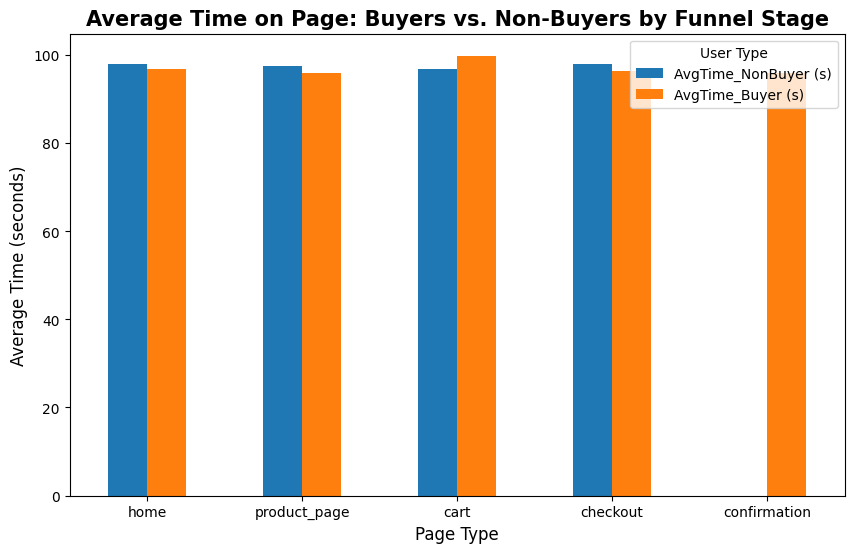

In [21]:
# Average Time on Page by Funnel Stage and Purchase Status ---

# Calculate average time spent on each page type, segmented by purchase status
time_stage_purchase = df.groupby(['PageType', 'Purchased'])['TimeOnPage_seconds'].mean().unstack()

# Rename columns for clarity
time_stage_purchase.columns = ['AvgTime_NonBuyer (s)', 'AvgTime_Buyer (s)']

# Reorder index to follow funnel steps
time_stage_purchase = time_stage_purchase.reindex(funnel_steps)

print("\nAverage Time Spent on Page by Funnel Stage (Seconds):")
display(time_stage_purchase.style.format('{:.2f} s'))

# Plotting the comparison
time_stage_purchase.plot(kind='bar', figsize=(10, 6), rot=0)
plt.title('Average Time on Page: Buyers vs. Non-Buyers by Funnel Stage', fontsize=15, weight='bold')
plt.xlabel('Page Type', fontsize=12)
plt.ylabel('Average Time (seconds)', fontsize=12)
plt.legend(title='User Type')
plt.show()


Conversion Rate by Device Type and Referral Source:


ReferralSource,Direct,Email,Google,Social Media
DeviceType,,,,
Desktop,41.47%,36.97%,41.71%,39.81%
Mobile,39.80%,37.84%,42.34%,38.05%
Tablet,36.77%,42.40%,41.67%,37.25%


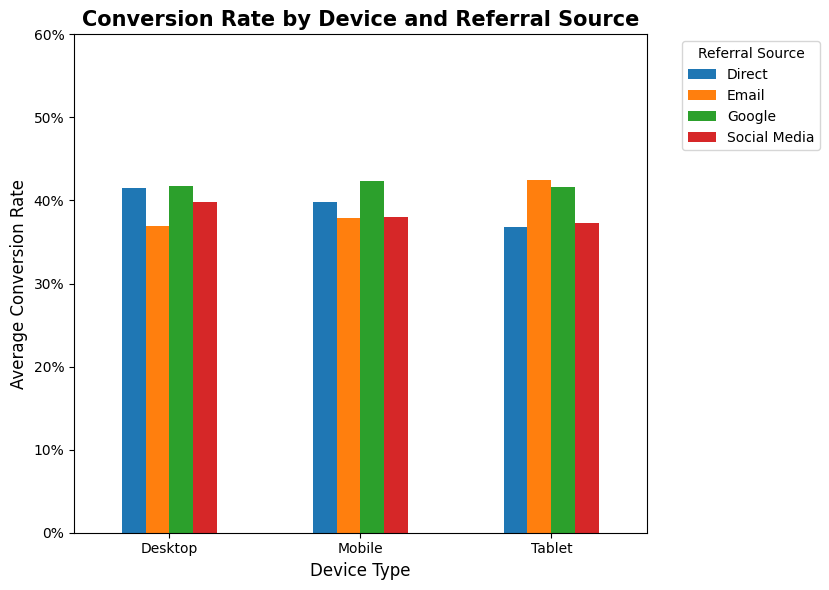

In [22]:
# Conversion Rate by Device and Referral Source Interaction ---

interaction_conv = df.groupby(['DeviceType', 'ReferralSource'])['Purchased'].mean().unstack()

print("\nConversion Rate by Device Type and Referral Source:")
display(interaction_conv.style.format('{:.2%}')) # Format as percentage

# Plotting the interaction
interaction_conv.plot(kind='bar', figsize=(10, 6), rot=0)
plt.title('Conversion Rate by Device and Referral Source', fontsize=15, weight='bold')
plt.xlabel('Device Type', fontsize=12)
plt.ylabel('Average Conversion Rate', fontsize=12)
plt.ylim(0, 0.6) # Adjust ylim if needed
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter('{:.0%}'.format)) # Format y-axis as percentage
plt.legend(title='Referral Source', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout(rect=[0, 0, 0.85, 1]) # Adjust layout to make space for legend
plt.show()


Average Number of Pages Visited per Session:


,Purchased,PageCount
0,0,1.922055
1,1,5.000000


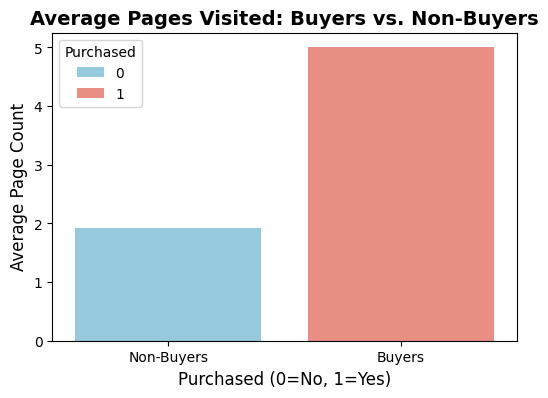

In [23]:
# Average Number of Pages Visited per Session ---

# Calculate the number of pages visited in each session
pages_per_session = df.groupby('SessionID')['PageType'].count()

# Add this page count back to the original dataframe (map by SessionID)
# We only need one entry per session, so let's merge with a dataframe containing unique SessionIDs and their purchase status
session_purchase_status = df[['SessionID', 'Purchased']].drop_duplicates('SessionID')
session_metrics = session_purchase_status.merge(pages_per_session.rename('PageCount'), on='SessionID')

# Calculate the average page count for buyers vs non-buyers
avg_page_count = session_metrics.groupby('Purchased')['PageCount'].mean().reset_index()


print("\nAverage Number of Pages Visited per Session:")
display(avg_page_count)

# Plotting the comparison
plt.figure(figsize=(6, 4))
sns.barplot(data=avg_page_count, x='Purchased', y='PageCount', palette=['skyblue', 'salmon'], hue='Purchased')
plt.title('Average Pages Visited: Buyers vs. Non-Buyers', fontsize=14, weight='bold')
plt.xlabel('Purchased (0=No, 1=Yes)', fontsize=12)
plt.ylabel('Average Page Count', fontsize=12)
plt.xticks([0, 1], ['Non-Buyers', 'Buyers'])
plt.show()

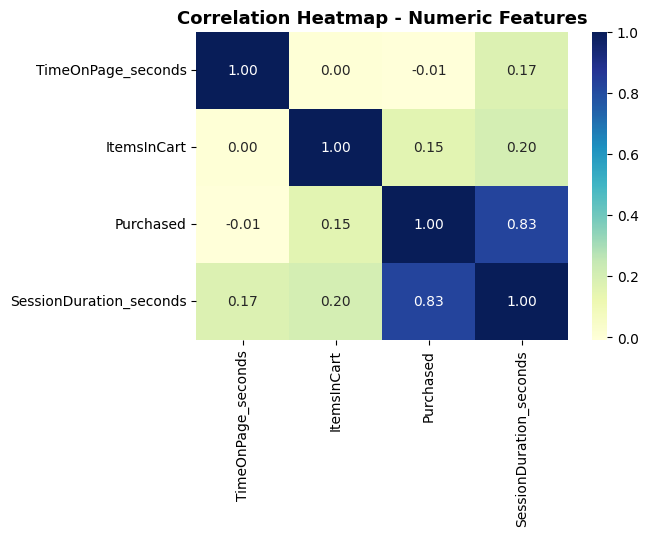

In [24]:
# Keep only numeric columns for correlation
num_df = df.select_dtypes(include=['int64','float64'])

# Compute correlation matrix
corr = num_df.corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap='YlGnBu', fmt=".2f")
plt.title('Correlation Heatmap - Numeric Features', fontsize=13, weight='bold')
plt.show()

Overall Bounce Rate: 20.26%
\nBounce Rate by Landing Page:


,LandingPage,BounceRate
0,home,20.26%


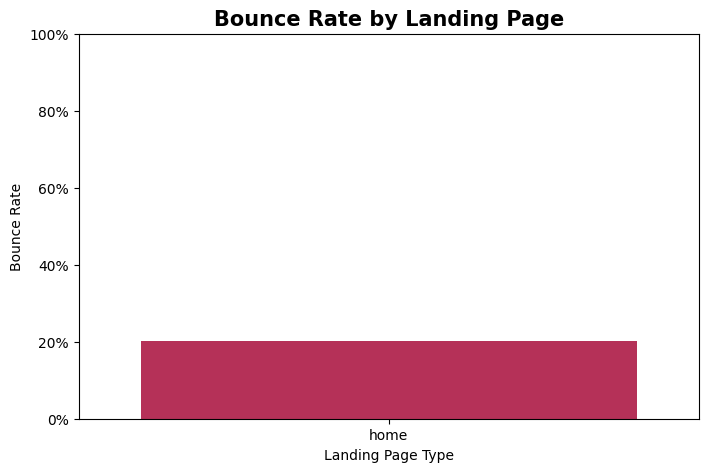

In [25]:
# Bounce Rate ---

# Calculate the number of pages visited per session
pages_per_session = df.groupby('SessionID')['PageType'].count()

# Identify single-page sessions (bounces)
bounced_sessions = pages_per_session[pages_per_session == 1].index

# Calculate overall bounce rate
total_sessions = df['SessionID'].nunique()
bounce_rate = len(bounced_sessions) / total_sessions
print(f"Overall Bounce Rate: {bounce_rate:.2%}")

# Analyze bounce rate by the first page visited
first_page_df = df.loc[df.groupby('SessionID')['Timestamp'].idxmin()] # Get the first action of each session
bounces_by_first_page = first_page_df[first_page_df['SessionID'].isin(bounced_sessions)]['PageType'].value_counts()
total_by_first_page = first_page_df['PageType'].value_counts()

bounce_rate_by_page = (bounces_by_first_page / total_by_first_page).fillna(0).reset_index()
bounce_rate_by_page.columns = ['LandingPage', 'BounceRate']

print("\\nBounce Rate by Landing Page:")
display(bounce_rate_by_page.style.format({'BounceRate': '{:.2%}'}))

# Optional: Plot bounce rate by landing page
plt.figure(figsize=(8, 5))
sns.barplot(data=bounce_rate_by_page, x='LandingPage', y='BounceRate', hue='LandingPage', palette='rocket')
plt.title('Bounce Rate by Landing Page', fontsize=15, weight='bold')
plt.ylabel('Bounce Rate')
plt.xlabel('Landing Page Type')
plt.ylim(0, 1)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter('{:.0%}'.format))
plt.show()

In [26]:
# Cart Abandonment Segmentation ---

# Identify sessions that reached the cart
cart_sessions = df[df['PageType'] == 'cart']['SessionID'].unique()

# Identify sessions that reached cart BUT did NOT purchase, We need purchase status per session (get it from session_metrics we created earlier or recreate)
if 'session_metrics' not in locals(): # Recreate if not available
     pages_per_session = df.groupby('SessionID')['PageType'].count()
     session_purchase_status = df[['SessionID', 'Purchased']].drop_duplicates('SessionID')
     session_metrics = session_purchase_status.merge(pages_per_session.rename('PageCount'), on='SessionID')

abandoned_cart_sessions = session_metrics[
    (session_metrics['SessionID'].isin(cart_sessions)) &
    (session_metrics['Purchased'] == 0)
]['SessionID']

# Filter the original dataframe for these abandoned sessions
df_abandoned = df[df['SessionID'].isin(abandoned_cart_sessions)]

print(f"Number of sessions that abandoned the cart: {len(abandoned_cart_sessions)}")

# Analyze characteristics of abandoned cart sessions (example: by device)
abandoned_device_dist = df_abandoned.drop_duplicates('SessionID')['DeviceType'].value_counts(normalize=True).reset_index()
abandoned_device_dist.columns = ['DeviceType', 'Percentage']

print("\nDevice Distribution for Cart Abandonment:")
display(abandoned_device_dist.style.format({'Percentage': '{:.2%}'}))

# Example: Analyze by Referral Source
abandoned_source_dist = df_abandoned.drop_duplicates('SessionID')['ReferralSource'].value_counts(normalize=True).reset_index()
abandoned_source_dist.columns = ['ReferralSource', 'Percentage']

print("\nReferral Source Distribution for Cart Abandonment:")
display(abandoned_source_dist.style.format({'Percentage': '{:.2%}'}))

Number of sessions that abandoned the cart: 589

Device Distribution for Cart Abandonment:


,DeviceType,Percentage
0,Mobile,33.96%
1,Tablet,33.79%
2,Desktop,32.26%



Referral Source Distribution for Cart Abandonment:


,ReferralSource,Percentage
0,Email,26.66%
1,Google,25.47%
2,Direct,24.28%
3,Social Media,23.60%


In [27]:
# Split data into converters and non-converters
buyers = df[df['Purchased'] == 1]
non_buyers = df[df['Purchased'] == 0]

# Compare average engagement metrics
comparison = pd.DataFrame({
    'Metric': ['TimeOnPage_seconds', 'ItemsInCart'],
    'Avg (Purchased=1)': [buyers['TimeOnPage_seconds'].mean(), buyers['ItemsInCart'].mean()],
    'Avg (Purchased=0)': [non_buyers['TimeOnPage_seconds'].mean(), non_buyers['ItemsInCart'].mean()]
})

print("Average Comparison of Engagement Metrics:")
display(comparison)

Average Comparison of Engagement Metrics:


,Metric,Avg (Purchased=1),Avg (Purchased=0)
0,TimeOnPage_seconds,96.994455,97.713000
1,ItemsInCart,1.460396,0.926588


In [28]:
#Simple User Path (Next Step) ---

# Sort by session and timestamp to easily find the next step
df_sorted = df.sort_values(['SessionID', 'Timestamp'])

# Find the next page visited within each session
df_sorted['NextPageType'] = df_sorted.groupby('SessionID')['PageType'].shift(-1)

# --- Path from 'home' page ---
home_next_step = df_sorted[df_sorted['PageType'] == 'home'].groupby(['NextPageType', 'Purchased']).size().unstack(fill_value=0)
home_next_step.columns = ['NonBuyer_Count', 'Buyer_Count'] # Rename for clarity
print("\nMost Common Next Page from 'home':")
display(home_next_step.sort_values(by=['NonBuyer_Count', 'Buyer_Count'], ascending=False))


# --- Path from 'product_page' page ---
product_next_step = df_sorted[df_sorted['PageType'] == 'product_page'].groupby(['NextPageType', 'Purchased']).size().unstack(fill_value=0)
product_next_step.columns = ['NonBuyer_Count', 'Buyer_Count'] # Rename for clarity
print("\nMost Common Next Page from 'product_page':")
display(product_next_step.sort_values(by=['NonBuyer_Count', 'Buyer_Count'], ascending=False))


Most Common Next Page from 'home':


,NonBuyer_Count,Buyer_Count
NextPageType,,
product_page,2977,1010



Most Common Next Page from 'product_page':


,NonBuyer_Count,Buyer_Count
NextPageType,,
cart,589,1010


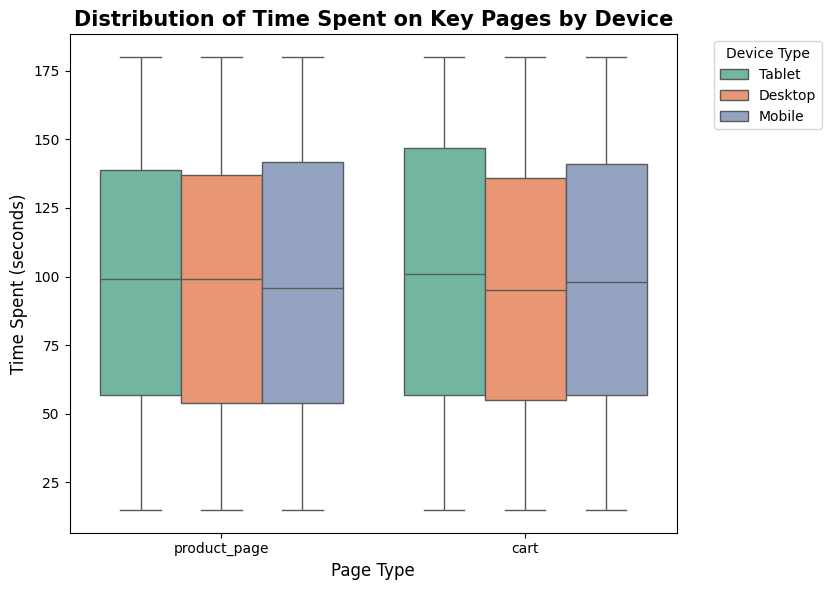

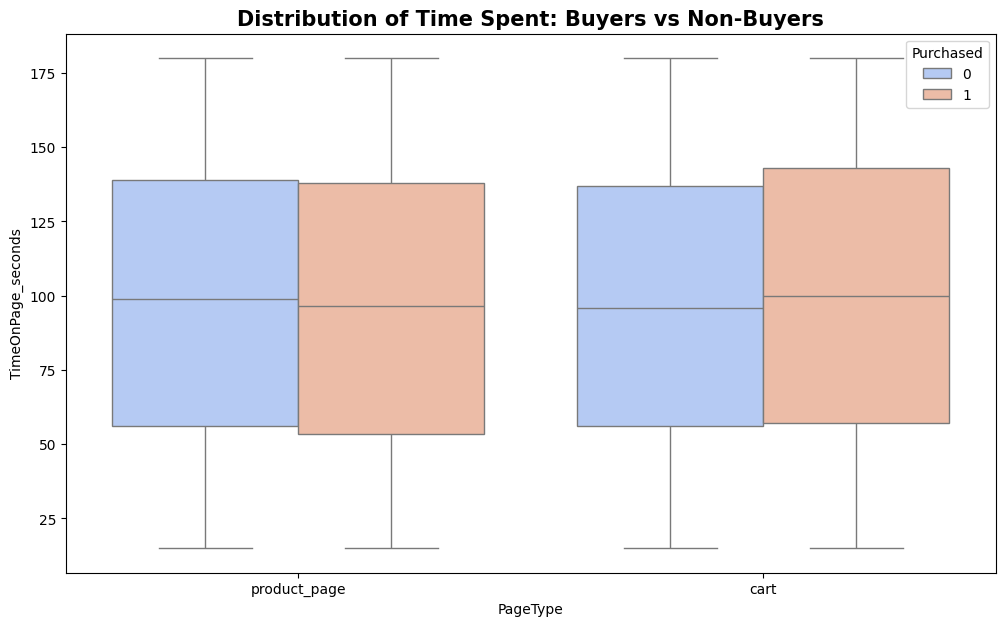

In [29]:
# Time Spent Distribution on Key Pages by Device ---

# Focus on product and cart pages
key_pages_df = df[df['PageType'].isin(['product_page', 'cart'])]

plt.figure(figsize=(10, 6))
sns.boxplot(data=key_pages_df, x='PageType', y='TimeOnPage_seconds', hue='DeviceType', palette='Set2')
plt.title('Distribution of Time Spent on Key Pages by Device', fontsize=15, weight='bold')
plt.xlabel('Page Type', fontsize=12)
plt.ylabel('Time Spent (seconds)', fontsize=12)
plt.legend(title='Device Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

# Optional: Also look at it segmented by purchase status
plt.figure(figsize=(12, 7))
sns.boxplot(data=key_pages_df, x='PageType', y='TimeOnPage_seconds', hue='Purchased', palette='coolwarm')
plt.title('Distribution of Time Spent: Buyers vs Non-Buyers', fontsize=15, weight='bold')
#... (add labels etc.)
plt.show()